# Handwritten Character Recognition using CNN

## 1. Project Overview
This project focuses on recognizing handwritten digits (0–9) using a Convolutional Neural Network (CNN). The model is trained on the MNIST dataset, which contains 70,000 grayscale handwritten digit images.

## 2. Dataset
- Dataset: MNIST Handwritten Digits
- Total images: 70,000
- Training images: 60,000
- Testing images: 10,000
- Image dimensions: 28 × 28 pixels
- Classes: Digits 0 to 9

## 3. Technologies Used
- Python
- Google Colab
- TensorFlow and Keras
- NumPy
- Matplotlib
- Scikit-learn
- Seaborn

## 4. Model Architecture
A Convolutional Neural Network (CNN) was developed using:
- Convolutional layers
- Max Pooling layers
- Flatten layer
- Dense layer
- Dropout layer
- Softmax output layer

## 5. Project Workflow
1. Imported the required libraries.
2. Loaded the MNIST dataset.
3. Visualized handwritten digit images.
4. Normalized and reshaped the images.
5. Built the CNN architecture.
6. Compiled and trained the model.
7. Evaluated the model on test data.
8. Generated predictions.
9. Created a classification report and confusion matrix.
10. Saved the trained model.

## 6. Training Configuration
- Epochs: 5
- Batch size: 64
- Optimizer: Adam
- Loss function: Sparse Categorical Crossentropy
- Validation split: 10%

## 7. Results
- Training accuracy: 98.62%
- Validation accuracy: 99.10%
- Test accuracy: 99.14%
- Test loss: 0.0271

## 8. Conclusion
The CNN model successfully recognizes handwritten digits from the MNIST dataset and achieved 99.14% test accuracy. The project demonstrates how deep learning and convolutional neural networks can be used for image classification and handwritten digit recognition.

## 9. Project Output
The trained model is saved as `handwritten_digit_model.keras` and can be loaded for future predictions.

**Note:** This project is developed for educational and internship purposes.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from sklearn.metrics import classification_report, confusion_matrix

In [2]:
# Load the MNIST dataset
(X_train, y_train), (X_test, y_test) = mnist.load_data()

# Display dataset shapes
print("Training images:", X_train.shape)
print("Training labels:", y_train.shape)

print("Testing images:", X_test.shape)
print("Testing labels:", y_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training images: (60000, 28, 28)
Training labels: (60000,)
Testing images: (10000, 28, 28)
Testing labels: (10000,)


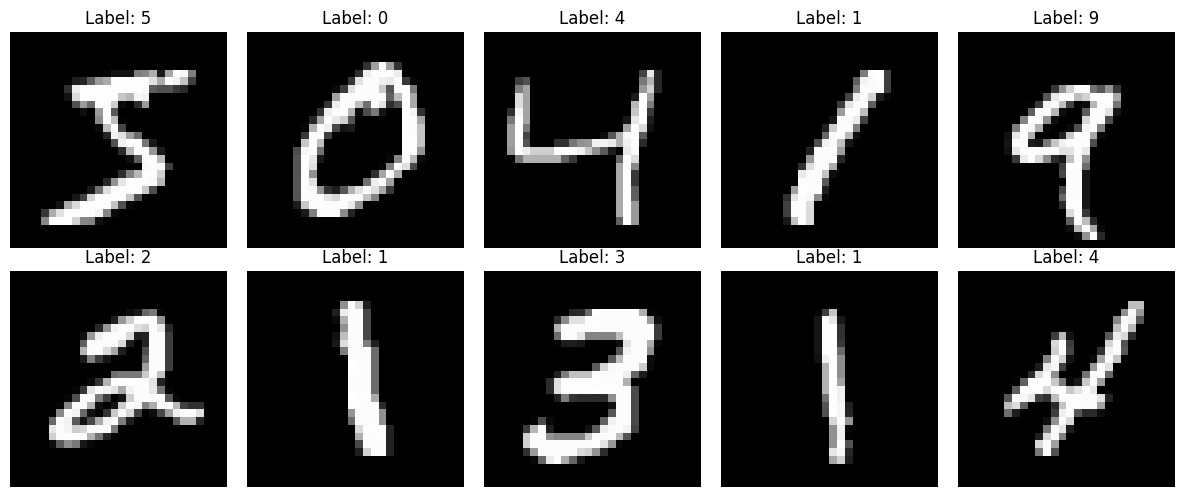

In [4]:
# Display the first 10 images
plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i], cmap='gray')
    plt.title(f"Label: {y_train[i]}")
    plt.axis('off')

plt.tight_layout()
plt.show()

In [5]:
# Normalize pixel values
X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

# Reshape images for CNN
X_train = X_train.reshape(-1, 28, 28, 1)
X_test = X_test.reshape(-1, 28, 28, 1)

# Check the new shapes
print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("Minimum pixel value:", X_train.min())
print("Maximum pixel value:", X_train.max())

Training data shape: (60000, 28, 28, 1)
Testing data shape: (10000, 28, 28, 1)
Minimum pixel value: 0.0
Maximum pixel value: 1.0


In [6]:
# Build the CNN model
model = Sequential([
    # First convolution layer
    Conv2D(32, (3, 3), activation='relu',
           input_shape=(28, 28, 1)),

    # Reduce image dimensions
    MaxPooling2D((2, 2)),

    # Second convolution layer
    Conv2D(64, (3, 3), activation='relu'),

    # Reduce image dimensions again
    MaxPooling2D((2, 2)),

    # Convert feature maps into a single vector
    Flatten(),

    # Fully connected layer
    Dense(128, activation='relu'),

    # Reduce overfitting
    Dropout(0.5),

    # Output layer for digits 0 to 9
    Dense(10, activation='softmax')
])

# Display model architecture
model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:
# Compile the CNN model
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("Model compiled successfully!")

Model compiled successfully!


In [8]:
# Train the CNN model
history = model.fit(
    X_train,
    y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.1
)

Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 50s 57ms/step - accuracy: 0.9185 - loss: 0.2642 - val_accuracy: 0.9815 - val_loss: 0.0618
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 47s 55ms/step - accuracy: 0.9731 - loss: 0.0914 - val_accuracy: 0.9873 - val_loss: 0.0442
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 48s 57ms/step - accuracy: 0.9796 - loss: 0.0680 - val_accuracy: 0.9882 - val_loss: 0.0395
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 83s 57ms/step - accuracy: 0.9838 - loss: 0.0525 - val_accuracy: 0.9905 - val_loss: 0.0319
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 80s 55ms/step - accuracy: 0.9862 - loss: 0.0452 - val_accuracy: 0.9910 - val_loss: 0.0336


In [9]:
# Evaluate the model
test_loss, test_accuracy = model.evaluate(X_test, y_test)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy * 100, "%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.9914 - loss: 0.0271
Test Loss: 0.027148563414812088
Test Accuracy: 99.14000034332275 %


In [10]:
# Generate predictions
y_pred_prob = model.predict(X_test)

# Convert probabilities into predicted digit labels
y_pred = np.argmax(y_pred_prob, axis=1)

# Display first 10 predictions
print("Actual labels:   ", y_test[:10])
print("Predicted labels:", y_pred[:10])

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step
Actual labels:    [7 2 1 0 4 1 4 9 5 9]
Predicted labels: [7 2 1 0 4 1 4 9 5 9]


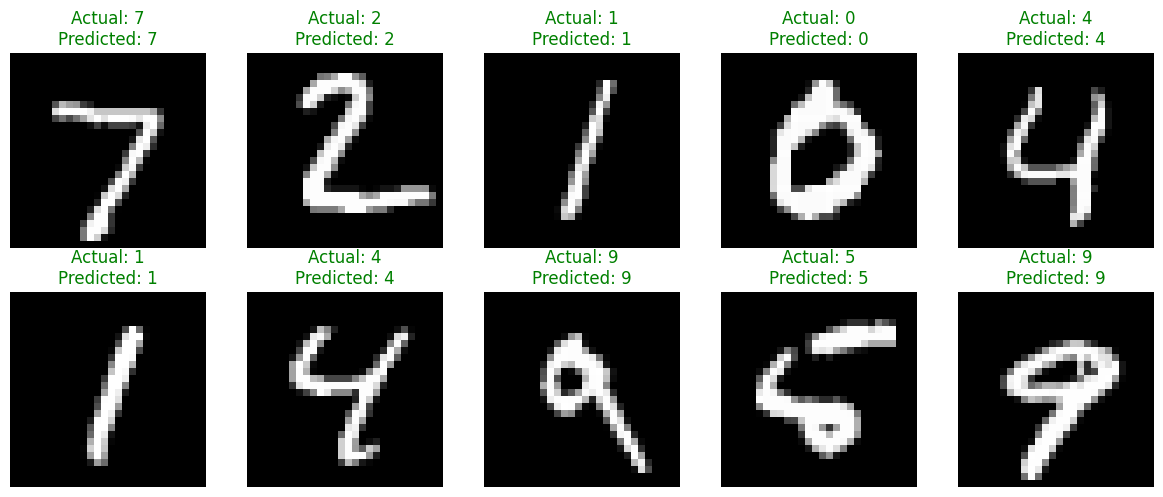

In [11]:
# Display first 10 test images with predictions
plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_test[i].reshape(28, 28), cmap='gray')

    color = 'green' if y_test[i] == y_pred[i] else 'red'

    plt.title(
        f"Actual: {y_test[i]}\nPredicted: {y_pred[i]}",
        color=color
    )
    plt.axis('off')

plt.tight_layout()
plt.show()

In [12]:
# Generate classification report
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.99      1.00      0.99       980
           1       0.99      1.00      1.00      1135
           2       0.99      0.99      0.99      1032
           3       1.00      0.99      0.99      1010
           4       1.00      0.99      0.99       982
           5       0.99      0.99      0.99       892
           6       1.00      0.99      0.99       958
           7       0.98      0.99      0.99      1028
           8       0.99      0.99      0.99       974
           9       0.99      0.99      0.99      1009

    accuracy                           0.99     10000
   macro avg       0.99      0.99      0.99     10000
weighted avg       0.99      0.99      0.99     10000



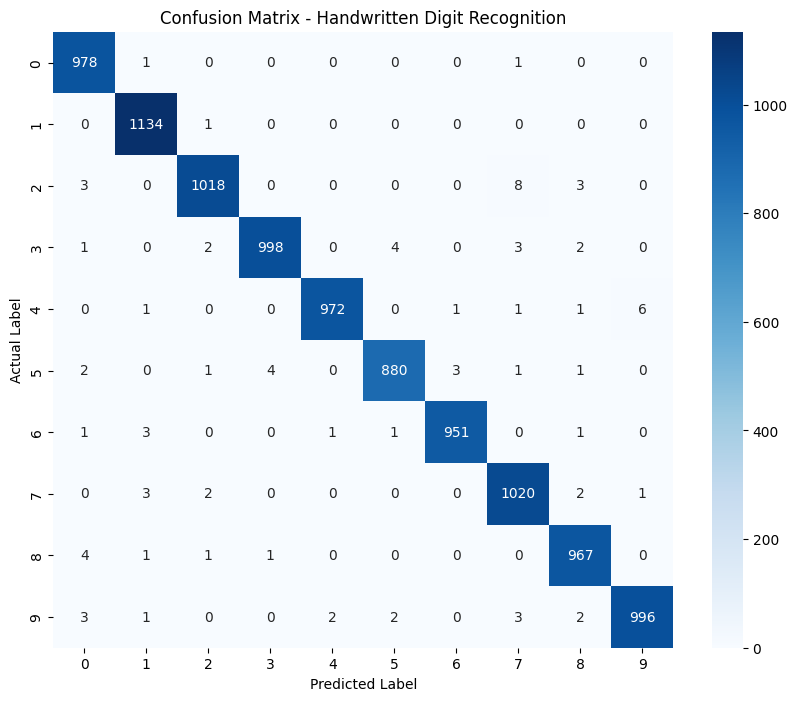

In [13]:
import seaborn as sns

# Create confusion matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix - Handwritten Digit Recognition")
plt.show()

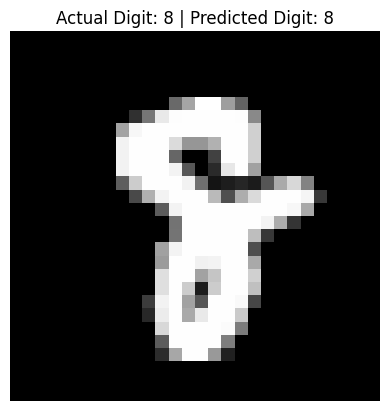

Actual Digit: 8
Predicted Digit: 8


In [14]:
# Select a random test image
index = np.random.randint(0, len(X_test))

# Get the image and actual label
image = X_test[index]
actual_digit = y_test[index]

# Predict the digit
prediction = model.predict(
    image.reshape(1, 28, 28, 1),
    verbose=0
)

predicted_digit = np.argmax(prediction)

# Display the image
plt.imshow(image.reshape(28, 28), cmap='gray')
plt.title(
    f"Actual Digit: {actual_digit} | Predicted Digit: {predicted_digit}"
)
plt.axis('off')
plt.show()

print("Actual Digit:", actual_digit)
print("Predicted Digit:", predicted_digit)

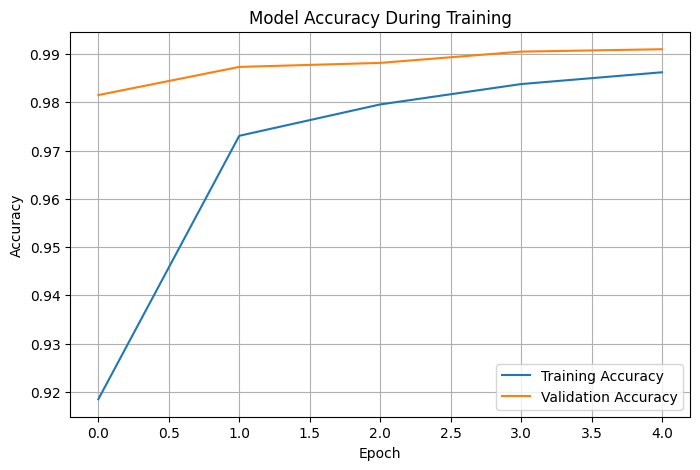

In [15]:
# Plot training and validation accuracy
plt.figure(figsize=(8, 5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title('Model Accuracy During Training')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

In [16]:
# Save the trained model
model.save('/content/handwritten_digit_model.keras')

print("Model saved successfully!")

Model saved successfully!


In [17]:
from google.colab import files

files.download('/content/handwritten_digit_model.keras')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>